# Causal trees, from scratch: who benefits from surgery?

**Question:** the ATE says surgery helps *on average*. Which patients does it help, by how much, and how sure are we
about each subgroup? Athey & Imbens (2016) answer with a tree whose leaves are subgroups with different treatment
effects, built so that each leaf's confidence interval is valid even though the subgroups were found by searching the
data.

| § | Idea |
|---|---|
| 1 | Why a regression tree on $Y$ is not a tree on $\tau$, and the transformed-outcome trick |
| 2 | An honest causal tree on a randomized trial with irrelevant covariates |
| 3 | Adaptive estimation is biased: the "winner's curse" of choosing a split |
| 4 | Coverage of leaf confidence intervals: adaptive vs honest (the paper's main result) |
| 5 | Split criteria compared: transformed outcome, adaptive, honest |
| 6 | Observational data: inverse-propensity weights inside the leaves |
| 7 | **slider:** minimum leaf size |

The tree is [`src/tree.py`](../src/tree.py) (≈200 lines of NumPy). The data are the course's running example
([`src/hospital.py`](../src/hospital.py)) with age and noise covariates added.

In [1]:
import sys
sys.path.insert(0, "..")

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as w

from src.hospital import make_hospital
from src.tree import CausalTree, leaf_effect, cv_alpha

plt.rcParams["figure.dpi"] = 100

## 1. The target is not observed

A CART regression tree chooses splits that reduce $\sum_i (Y_i - \hat\mu(X_i))^2$. For effects we would want
$\sum_i (\tau_i - \hat\tau(X_i))^2$, but $\tau_i = Y_i(1) - Y_i(0)$ is never observed: the "fundamental problem of causal
inference" also breaks cross-validation.

Two ways around it:

* **Transformed outcome (TOT).** In a trial with $P(T=1) = p$, $Y^* = Y\,\frac{T - p}{p(1-p)}$ satisfies
  $E[Y^* | X] = \tau(X)$. So grow an ordinary regression tree on $Y^*$. It works, but $Y^*$ is very noisy: it ignores
  that each leaf contains treated *and* control units.
* **Causal tree.** Estimate $\hat\tau_\ell = \bar Y_{\ell,1} - \bar Y_{\ell,0}$ in each leaf, and pick splits with a
  criterion that is an unbiased estimate of $-\text{MSE}(\tau)$ up to a constant:

$$
-\widehat{\text{EMSE}}(\Pi) = \underbrace{\frac{1}{N^{tr}} \sum_{i} \hat\tau^2(X_i)}_{\text{reward heterogeneity}}
\; - \; \underbrace{\Big(\frac{1}{N^{tr}} + \frac{1}{N^{est}}\Big) \sum_{\ell \in \Pi} \Big(\frac{S^2_{\ell,1}}{p} + \frac{S^2_{\ell,0}}{1 - p}\Big)}_{\text{penalize noisy leaves}}
$$

The first term grows with every split; the second grows too, because small leaves have noisy estimates. A split is
made only if it separates effects by more than it adds variance.

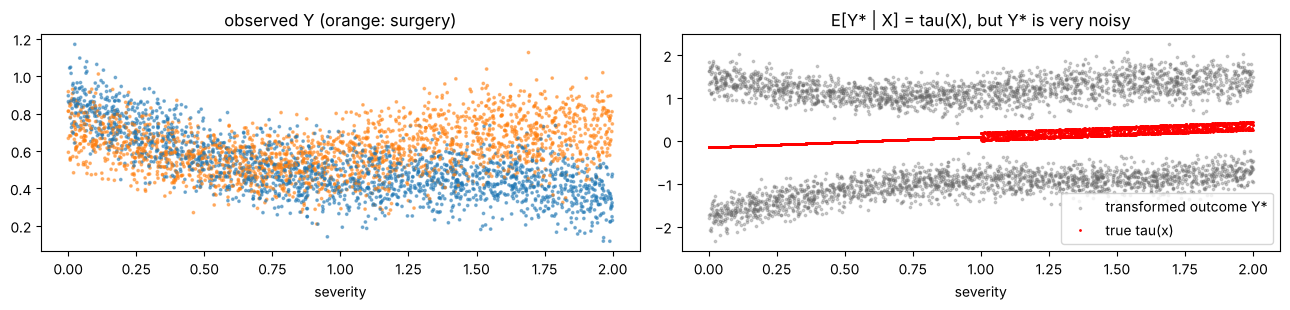

sd of Y* = 1.18   vs   sd of tau(X) = 0.15


In [2]:
d = make_hospital(4000, seed=0, n_noise=4, nonlinear=True, randomized=True)
ystar = d.Y * (d.T - 0.5) / 0.25
fig, ax = plt.subplots(1, 2, figsize=(13, 3.2))
ax[0].scatter(d.S, d.Y, c=np.where(d.T == 1, "tab:orange", "tab:blue"), s=3, alpha=0.5)
ax[0].set_title("observed Y (orange: surgery)"); ax[0].set_xlabel("severity")
ax[1].scatter(d.S, ystar, s=3, alpha=0.3, color="0.4", label="transformed outcome Y*")
o = np.argsort(d.S); ax[1].plot(d.S[o], d.tau[o], "r.", ms=2, label="true tau(x)")
ax[1].set_xlabel("severity"); ax[1].legend(); ax[1].set_title("E[Y* | X] = tau(X), but Y* is very noisy")
plt.tight_layout(); plt.show()
print(f"sd of Y* = {ystar.std():.2f}   vs   sd of tau(X) = {d.tau.std():.2f}")

## 2. An honest causal tree

A randomized trial with 4000 patients and six covariates: severity, age (which modifies the effect only for severe
patients) and four pure-noise variables. Half the data grows the tree with the honest criterion, the other half
estimates each leaf's effect.

In [3]:
alphas = np.array([0, 1e-5, 3e-5, 1e-4, 3e-4, 1e-3])
alpha, cv_loss = cv_alpha(d.X, d.T, d.Y, alphas, min_leaf=60, max_depth=6)
print("5-fold CV loss mean((Y* - tau_hat)^2) per leaf penalty:")
for a, l in zip(alphas, cv_loss):
    print(f"  alpha = {a:<7g} {l:.5f}{'   <- chosen' if a == alpha else ''}")
ct = CausalTree(criterion="honest", min_leaf=60, max_depth=6, alpha=alpha, seed=0).fit(d.X, d.T, d.Y)
print()
print(ct.describe(list(d.names)))

5-fold CV loss mean((Y* - tau_hat)^2) per leaf penalty:
  alpha = 0       1.36197
  alpha = 1e-05   1.36188
  alpha = 3e-05   1.36170
  alpha = 0.0001  1.36091   <- chosen
  alpha = 0.0003  1.36186
  alpha = 0.001   1.36374

severity <= 0.98
  severity <= 0.55
    severity <= 0.08
      leaf 0: tau = -0.151 ± 0.043  (n_est = 85)
    severity >  0.08
      leaf 1: tau = -0.078 ± 0.021  (n_est = 489)
  severity >  0.55
    noise3 <= 0.80
      severity <= 0.76
        leaf 2: tau = +0.014 ± 0.029  (n_est = 168)
      severity >  0.76
        leaf 3: tau = +0.051 ± 0.033  (n_est = 174)
    noise3 >  0.80
      leaf 4: tau = +0.043 ± 0.039  (n_est = 99)
severity >  0.98
  age <= 0.58
    severity <= 1.35
      leaf 5: tau = +0.086 ± 0.029  (n_est = 226)
    severity >  1.35
      age <= 0.43
        severity <= 1.82
          leaf 6: tau = +0.184 ± 0.029  (n_est = 189)
        severity >  1.82
          leaf 7: tau = +0.272 ± 0.045  (n_est = 77)
      age >  0.43
        leaf 8: tau = +0.2

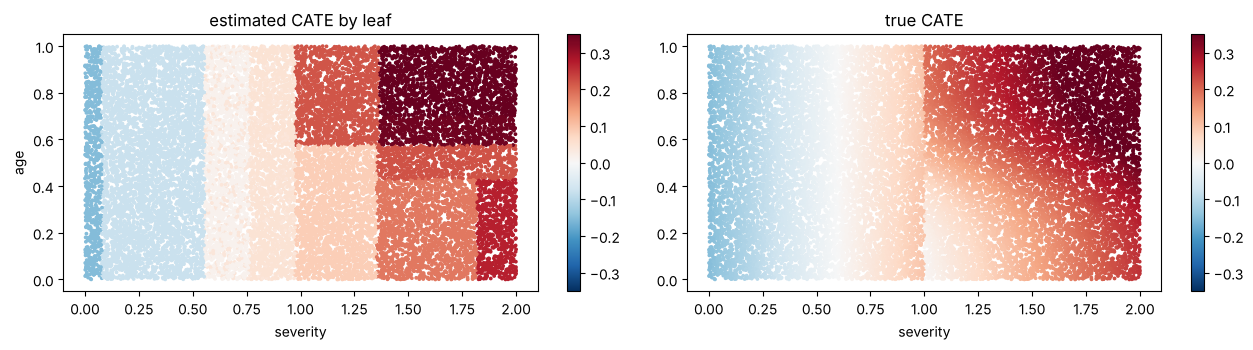

leaves: 13   RMSE of tau_hat on new patients: 0.039   (predicting the ATE everywhere: 0.153)
splits per feature: {'severity': 7, 'noise3': 1, 'age': 3, 'noise0': 1}


In [4]:
dt = make_hospital(20000, seed=123, n_noise=4, nonlinear=True, randomized=True)
pred = ct.predict(dt.X)
fig, ax = plt.subplots(1, 2, figsize=(13, 3.6))
sc = ax[0].scatter(dt.S, dt.X[:, 1], c=pred, s=3, cmap="RdBu_r", vmin=-0.35, vmax=0.35)
ax[0].set_xlabel("severity"); ax[0].set_ylabel("age"); ax[0].set_title("estimated CATE by leaf"); plt.colorbar(sc, ax=ax[0])
sc = ax[1].scatter(dt.S, dt.X[:, 1], c=dt.tau, s=3, cmap="RdBu_r", vmin=-0.35, vmax=0.35)
ax[1].set_xlabel("severity"); ax[1].set_title("true CATE"); plt.colorbar(sc, ax=ax[1])
plt.tight_layout(); plt.show()
print(f"leaves: {ct.n_leaves}   RMSE of tau_hat on new patients: {np.sqrt(np.mean((pred - dt.tau) ** 2)):.3f}"
      f"   (predicting the ATE everywhere: {dt.tau.std():.3f})")
from collections import Counter
print("splits per feature:", dict(Counter(d.names[j] for j in ct.split_features())))

The tree splits on severity first (that is where most of the heterogeneity is), then on age among severe patients.
The honest criterion alone still accepts a few splits on noise columns: with 6 features and 32 thresholds per node,
the *best* noise split can beat the variance penalty by chance. As in CART, the paper adds a cost per leaf chosen by
cross-validation. The validation loss uses the transformed outcome, $\text{mean}\big((Y^*_i - \hat\tau(X_i))^2\big)$,
which equals the MSE of $\hat\tau$ plus a constant even though $\tau_i$ is never observed.

## 3. Why honesty: choosing a split biases its estimates

The paper's toy example: one binary feature $X \in \{L, R\}$ and **no** heterogeneity. An adaptive procedure splits
when the two estimated effects differ by more than a threshold $c$, then reports the two leaf estimates from the same
data. Conditional on having split, the reported difference is large *by construction*.

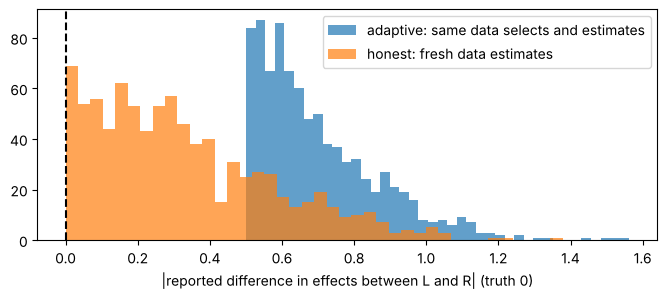

split in 874 of 4000 trials;  mean |gap| adaptive 0.70, honest 0.33


In [5]:
rng = np.random.default_rng(0)
gaps_adaptive, gaps_honest = [], []
for r in range(4000):
    n = 200
    X = rng.integers(0, 2, n); T = rng.integers(0, 2, n).astype(float)
    Y = 0.1 * T + rng.normal(size=n)                 # same effect (0.1) in both leaves
    def eff(m): return leaf_effect(Y[m], T[m])[0]
    half = np.arange(n) < n // 2
    g = eff(half & (X == 1)) - eff(half & (X == 0))  # selection on the first half
    if abs(g) > 0.5:
        gaps_adaptive.append(g)
        gaps_honest.append(eff(~half & (X == 1)) - eff(~half & (X == 0)))
fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(np.abs(gaps_adaptive), 40, alpha=0.7, label="adaptive: same data selects and estimates")
ax.hist(np.abs(gaps_honest), 40, alpha=0.7, label="honest: fresh data estimates")
ax.axvline(0, color="k", ls="--"); ax.set_xlabel("|reported difference in effects between L and R| (truth 0)")
ax.legend(); plt.show()
print(f"split in {len(gaps_adaptive)} of 4000 trials;  mean |gap| adaptive {np.mean(np.abs(gaps_adaptive)):.2f}, honest {np.mean(np.abs(gaps_honest)):.2f}")

## 4. Coverage: do the leaf confidence intervals mean anything?

For each replication: draw 1000 patients, grow a tree, and for every leaf build the textbook 95% interval
$\hat\tau_\ell \pm 1.96\,\widehat{\text{se}}_\ell$. Its target is the leaf's true average effect
$E[\tau(X) \mid X \in \ell]$, computed on 20,000 fresh patients. We compare

* **adaptive**: the conventional approach. Splits *and* leaf estimates use all 1000 patients; the depth is capped
  because the adaptive criterion never stops on its own;
* **honest**: 500 patients choose the partition with the honest criterion, the other 500 estimate the leaves.

In [6]:
def leaf_truth(tree, pop):
    leaf = tree.apply(pop.X)
    return np.array([pop.tau[leaf == k].mean() if (leaf == k).any() else np.nan for k in range(tree.n_leaves)])

def replicate(r, n=1000):
    dd = make_hospital(n, seed=1000 + r, n_noise=4, nonlinear=True, randomized=True)
    out = {}
    for name, tree in [("adaptive", CausalTree("adaptive", max_depth=3, min_leaf=40, honest=False, seed=r)),
                       ("honest", CausalTree("honest", max_depth=5, min_leaf=40, honest=True, seed=r))]:
        tree.fit(dd.X, dd.T, dd.Y)
        tau = np.array([l.tau for l in tree.leaves]); se = np.array([l.se for l in tree.leaves])
        truth = leaf_truth(tree, pop)
        ok = np.isfinite(se) & np.isfinite(truth)
        out[name] = dict(cover=np.mean(np.abs(tau[ok] - truth[ok]) <= 1.96 * se[ok]), leaves=tree.n_leaves,
                         rmse=np.sqrt(np.mean((tree.predict(pop.X) - pop.tau) ** 2)))
    return out

pop = make_hospital(20000, seed=777, n_noise=4, nonlinear=True, randomized=True)
res = [replicate(r) for r in range(60)]
print(f"{'':>9} | {'coverage of 95% CIs':>20} | {'leaves':>7} | {'RMSE of tau(x)':>14}")
for name in ["adaptive", "honest"]:
    c = np.mean([r[name]["cover"] for r in res]); L = np.mean([r[name]["leaves"] for r in res])
    e = np.mean([r[name]["rmse"] for r in res])
    print(f"{name:>9} | {c:>20.1%} | {L:>7.1f} | {e:>14.3f}")

          |  coverage of 95% CIs |  leaves | RMSE of tau(x)
 adaptive |                79.4% |     7.9 |          0.056
   honest |                94.9% |     9.2 |          0.060


Adaptive leaf intervals undercover: the leaves were chosen *because* their estimates looked different, so the
estimates are too extreme for their own intervals. Honest intervals are close to nominal, at the cost of using half
the data for estimation. This is the paper's headline: honesty buys valid inference on data-driven subgroups,
"without concern about invalidating inference due to multiple testing".

## 5. Split criteria, compared

Prediction error of $\hat\tau(x)$ on new patients as the sample grows, for the three criteria (all honest, all with the
same minimum leaf size).

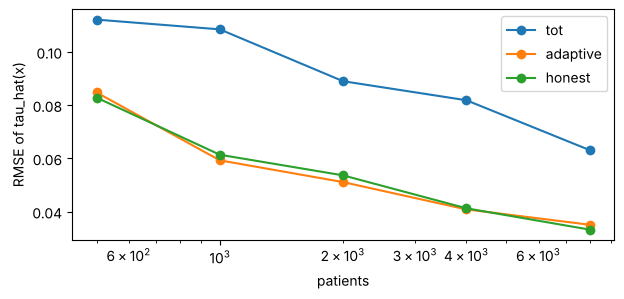

In [7]:
ns = [500, 1000, 2000, 4000, 8000]
crit = {"tot": dict(max_depth=4), "adaptive": dict(max_depth=4), "honest": dict(max_depth=8)}
err = {c: [] for c in crit}
for n in ns:
    for c, kw in crit.items():
        e = []
        for r in range(8):
            dd = make_hospital(n, seed=50 + r, n_noise=4, nonlinear=True, randomized=True)
            t = CausalTree(c, min_leaf=max(25, n // 80), seed=r, **kw).fit(dd.X, dd.T, dd.Y)
            e.append(np.sqrt(np.mean((t.predict(pop.X) - pop.tau) ** 2)))
        err[c].append(np.mean(e))
fig, ax = plt.subplots(figsize=(7, 3))
for c in crit:
    ax.plot(ns, err[c], "o-", label=c)
ax.set_xscale("log"); ax.set_xlabel("patients"); ax.set_ylabel("RMSE of tau_hat(x)"); ax.legend(); plt.show()

The transformed-outcome tree pays for the noise of $Y^*$. With a well-chosen depth cap, the adaptive criterion predicts
about as well as the honest one: honesty is not about better point predictions (it even gives up half the data for
estimation) but about the valid intervals of §4. The honest criterion also picks its own size, growing deeper as data
accumulate, where the adaptive one needs the cap tuned.

## 6. Observational data

With confounding, a raw difference of means inside a leaf is biased for the same reason as in
[01](../../../01-potential-outcomes/). Section 6 of the paper reweights units by inverse propensity inside each leaf.
Here we pass the true propensity (in practice, a fitted one).

In [8]:
do = make_hospital(4000, seed=3, n_noise=4, nonlinear=True)
for label, e in [("ignore confounding", None), ("propensity-weighted leaves", do.e)]:
    t = CausalTree("honest", min_leaf=60, seed=0).fit(do.X, do.T, do.Y, e=e)
    print(f"{label:>28}: RMSE {np.sqrt(np.mean((t.predict(pop.X) - pop.tau) ** 2)):.3f}, "
          f"implied ATE {t.predict(pop.X).mean():+.3f} (true {pop.ate:+.3f})")

          ignore confounding: RMSE 0.080, implied ATE +0.077 (true +0.099)


  propensity-weighted leaves: RMSE 0.048, implied ATE +0.096 (true +0.099)


## 7. Slider: minimum leaf size

Small leaves let the tree follow $\tau(x)$ closely but each leaf estimate is noisy; large leaves are precise but
coarse. The honest criterion already trades these off; the minimum leaf size is the remaining knob.

In [9]:
def leafsize(min_leaf=60):
    t = CausalTree("honest", min_leaf=min_leaf, max_depth=8, seed=0).fit(d.X, d.T, d.Y)
    p = t.predict(dt.X)
    fig, ax = plt.subplots(figsize=(8, 3.2))
    o = np.argsort(dt.S)
    ax.plot(dt.S[o], dt.tau[o], ".", ms=1, color="0.6", label="true tau(x)")
    ax.plot(dt.S[o], p[o], ".", ms=1.5, color="tab:red", label="tree")
    ax.set_xlabel("severity"); ax.set_ylim(-0.4, 0.6); ax.legend(markerscale=8, loc="upper left")
    ax.set_title(f"min_leaf = {min_leaf}: {t.n_leaves} leaves, RMSE {np.sqrt(np.mean((p - dt.tau) ** 2)):.3f}")
    plt.show()

w.interact(leafsize, min_leaf=w.IntSlider(value=60, min=10, max=400, step=10));

interactive(children=(IntSlider(value=60, description='min_leaf', max=400, min=10, step=10), Output()), _dom_c…

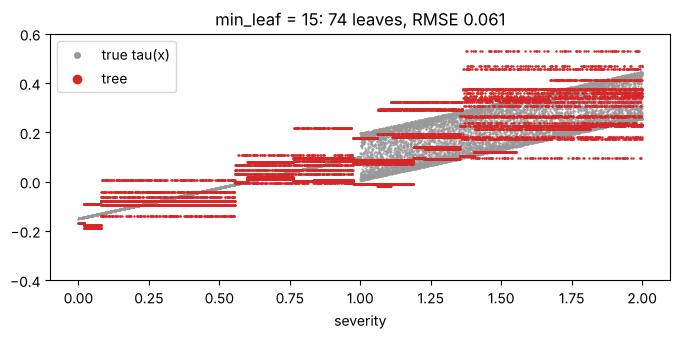

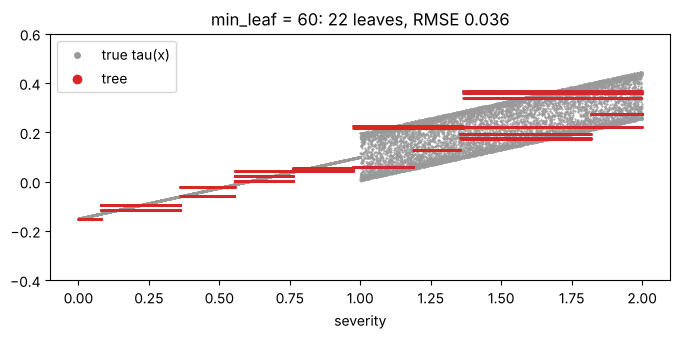

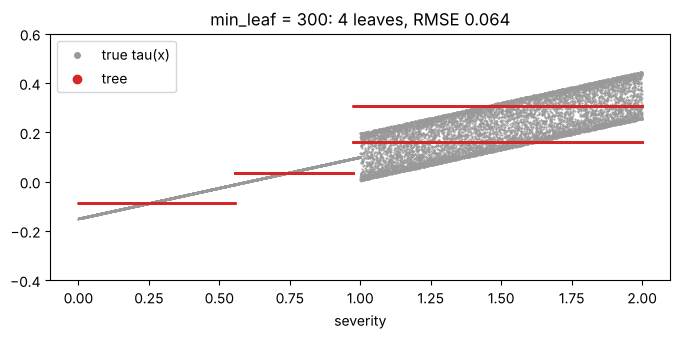

In [10]:
for m in [15, 60, 300]:
    leafsize(m)